# Imputing Missing Values

Real-world data is messy. Survey respondents skip questions, sensors go offline, and someone forgets to type a number into a spreadsheet. The result is **missing values**, and most machine-learning models in scikit-learn will simply refuse to run if they see one.

**Imputation** means *filling in missing values with sensible estimates*. In this notebook you will learn four ways to do it, from the simplest to the smartest:

| # | Method | Works for | Idea in one sentence |
|---|--------|-----------|----------------------|
| 1 | **Mean** imputation | numbers | Replace every gap with the column's average. |
| 2 | **Median** imputation | numbers | Replace every gap with the column's middle value. |
| 3 | **Random Forest Regressor** | numbers | *Predict* each missing number from the other columns. |
| 4 | **Random Forest Classifier** | categories | *Predict* each missing category from the other columns. |


## Table of contents
0. Setup
1. The dataset 
2. Punching holes: creating missing values
3. Exploring missing data
4. Option zero: just delete the rows?
5. Method 1: Mean imputation
6. Method 2: Median imputation (plus "most frequent" for categories)
7. The golden rule: avoid data leakage
8. Methods 3 & 4: Imputation with Random Forests
9. Summary cheat sheet

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.model_selection import train_test_split
import sklearn

# Make pandas show all columns and round floats nicely
pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 2)

# Slightly larger default plots
plt.rcParams["figure.figsize"] = (8, 4)


## 1. Our dataset (and why we built it ourselves)

We will **generate** a fake dataset about 500 university students. Why not use a real dataset?

Because with real data, when a value is missing **we never find out what it should have been**. That makes it impossible to say whether an imputation was good or bad. By creating the data ourselves we can:

1. Keep a complete copy, `df_true`, with **every true value**.
2. Deliberately delete some values to get `df`, the "messy" version.
3. Impute `df` and then **grade** each method by comparing it to `df_true`.

In real life you only ever have `df`. Keep that in mind throughout!

### The columns

| Column | Type | Meaning |
|--------|------|---------|
| `part_time_job` | category (`Yes`/`No`) | Does the student have a part-time job? |
| `study_hours` | number | Hours studied per week (students with jobs study a bit less) |
| `sleep_hours` | number | Average hours of sleep per night |
| `attendance` | number | Lecture attendance (%) |
| `commute_minutes` | number | One-way commute time. **Skewed**: most are short, a few are very long |
| `transport` | category (`Walk`/`Bus`/`Car`) | How they get to campus (related to commute time) |
| `exam_score` | number | Final exam score (0–100), which depends on the other columns |



In [13]:
rng = np.random.default_rng(seed=42)   # fixed seed -> everyone gets the same "random" data
n = 500

part_time_job = rng.choice(["Yes", "No"], size=n, p=[0.4, 0.6])
has_job = (part_time_job == "Yes").astype(int)

study_hours = np.clip(rng.normal(16, 5, n) - 3 * has_job, 0, 40).round(1)
sleep_hours = np.clip(rng.normal(7, 1, n), 4, 10).round(1)
attendance = np.clip(rng.normal(85, 10, n), 40, 100).round(0)

# Log-normal distribution -> right-skewed (long tail of very long commutes)
commute_minutes = np.clip(rng.lognormal(mean=3.0, sigma=0.6, size=n), 2, 180).round(0)

# Transport depends on commute time, plus 15% random "noise"
transport = np.where(commute_minutes < 15, "Walk",
             np.where(commute_minutes < 35, "Bus", "Car")).astype(object)
noise = rng.random(n) < 0.15
transport[noise] = rng.choice(["Walk", "Bus", "Car"], size=noise.sum())

exam_score = (30
              + 2.0 * study_hours
              + 3.0 * (sleep_hours - 7)
              + 0.3 * (attendance - 85)
              - 4.0 * has_job
              - 0.05 * commute_minutes
              + rng.normal(0, 5, n))
exam_score = np.clip(exam_score, 0, 100).round(1)

df_true = pd.DataFrame({
    "part_time_job": part_time_job,
    "study_hours": study_hours,
    "sleep_hours": sleep_hours,
    "attendance": attendance,
    "commute_minutes": commute_minutes,
    "transport": transport,
    "exam_score": exam_score,
})

df_true.head(10)

,part_time_job,study_hours,sleep_hours,attendance,commute_minutes,transport,exam_score
0,No,23.2,5.5,91.0,14.0,Walk,76.4
1,No,16.5,7.2,86.0,20.0,Bus,72.7
2,No,18.9,7.7,88.0,17.0,Bus,62.2
3,No,15.7,7.4,93.0,13.0,Walk,63.0
4,Yes,12.1,7.6,77.0,17.0,Bus,46.4
5,No,12.1,5.6,94.0,23.0,Bus,41.7
6,No,18.2,7.3,71.0,13.0,Walk,67.8
7,No,11.7,6.7,88.0,12.0,Walk,51.4
8,Yes,16.3,6.5,87.0,9.0,Walk,60.9
9,No,21.4,7.9,79.0,25.0,Bus,84.2


In [14]:
# A quick statistical summary of the COMPLETE data
df_true.describe()

,study_hours,sleep_hours,attendance,commute_minutes,exam_score
count,500.00,500.00,500.00,500.00,500.00
mean,14.53,7.02,83.13,24.07,55.85
std,5.23,1.03,9.63,16.38,12.60
min,0.00,4.00,55.00,3.00,20.50
25%,11.00,6.40,77.00,13.00,46.65
50%,14.70,7.00,84.00,21.00,56.45
75%,17.90,7.70,90.00,29.00,63.80
max,31.90,9.80,100.00,112.00,94.00


Look at `commute_minutes` in the summary above. The mean is noticeably **larger** than the median, and the max is far above the 75th percentile. That's the signature of a **right-skewed** distribution: a few students with very long commutes pull the average up. Remember this, because it will matter a lot in Section 6!
|

## 2. Creating missing values

Now let's make a "messy" copy called `df` and randomly delete some values:

* 15% of `study_hours`
* 10% of `sleep_hours`
* 15% of `commute_minutes`
* 15% of `transport`

`exam_score`, `attendance` and `part_time_job` stay complete.

In pandas, a missing value is shown as **`NaN`** ("Not a Number"). Even text columns use `NaN` (or `None`/`<NA>`) for missing entries.

### Side note: *why* is data missing?
Statisticians distinguish three situations. Which one you are in affects how trustworthy imputation is:

| Name | Meaning | Example |
|------|---------|---------|
| **MCAR** — Missing Completely At Random | Missingness has nothing to do with any value. | A coffee spill destroyed a few random survey pages. |
| **MAR** — Missing At Random | Missingness depends on *other observed* columns. | Students with jobs were more likely to skip the sleep question. |
| **MNAR** — Missing Not At Random | Missingness depends on the *missing value itself*. | Students who studied very little were embarrassed and left `study_hours` blank. |

Our holes below are **MCAR**: the easiest case. Exercise 3 at the end lets you explore the trickier MNAR case.

In [15]:
df = df_true.copy()   # .copy() is important! Otherwise changes to df would also change df_true

missing_rates = {
    "study_hours": 0.15,
    "sleep_hours": 0.10,
    "commute_minutes": 0.15,
    "transport": 0.15,
}

for col, rate in missing_rates.items():
    mask = rng.random(n) < rate      # True for roughly `rate` fraction of rows
    df.loc[mask, col] = np.nan       # delete those values

df.head(10)

,part_time_job,study_hours,sleep_hours,attendance,commute_minutes,transport,exam_score
0,No,23.2,5.5,91.0,14.0,NaN,76.4
1,No,16.5,7.2,86.0,20.0,Bus,72.7
2,No,18.9,7.7,88.0,17.0,Bus,62.2
3,No,15.7,7.4,93.0,13.0,Walk,63.0
4,Yes,12.1,7.6,77.0,17.0,Bus,46.4
5,No,12.1,NaN,94.0,23.0,Bus,41.7
6,No,18.2,7.3,71.0,13.0,Walk,67.8
7,No,11.7,6.7,88.0,12.0,Walk,51.4
8,Yes,16.3,6.5,87.0,9.0,Walk,60.9
9,No,21.4,7.9,79.0,25.0,Bus,84.2


You should now see some `NaN` values sprinkled through the table. From here on, **pretend you have never seen `df_true`**. It is our secret answer key, used *only* for grading.


## 3. Exploring missing data

Before fixing anything, always investigate. The key tool is **`.isna()`**, which returns a DataFrame of `True`/`False` values: `True` where data is missing.

Because `True` counts as 1 and `False` as 0, you can **sum** or **average** the result:
* `.isna().sum()` → *number* of missing values per column
* `.isna().mean()` → *fraction* of missing values per column

In [16]:
# What .isna() looks like for the first 5 rows
df.isna().head()

,part_time_job,study_hours,sleep_hours,attendance,commute_minutes,transport,exam_score
0,False,False,False,False,False,True,False
1,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False


In [17]:
missing_summary = pd.DataFrame({
    "n_missing": df.isna().sum(),
    "pct_missing": (df.isna().mean() * 100).round(1),
})
missing_summary

,n_missing,pct_missing
part_time_job,0,0.0
study_hours,68,13.6
sleep_hours,54,10.8
attendance,0,0.0
commute_minutes,61,12.2
transport,81,16.2
exam_score,0,0.0


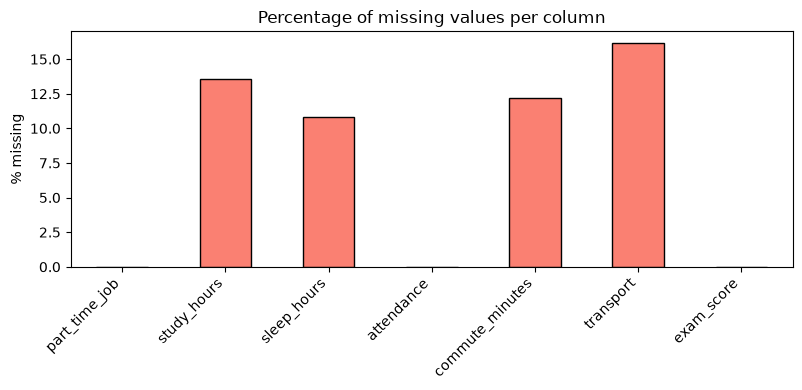

In [18]:
# A picture is worth a thousand numbers
missing_summary["pct_missing"].plot(kind="bar", color="salmon", edgecolor="black")
plt.ylabel("% missing")
plt.title("Percentage of missing values per column")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [19]:
# .info() is another quick way: compare "Non-Null Count" to the total number of rows
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   part_time_job    500 non-null    str    
 1   study_hours      432 non-null    float64
 2   sleep_hours      446 non-null    float64
 3   attendance       500 non-null    float64
 4   commute_minutes  439 non-null    float64
 5   transport        419 non-null    str    
 6   exam_score       500 non-null    float64
dtypes: float64(5), str(2)
memory usage: 30.1 KB


Each column is missing *at most* 15% of its values. 

In [20]:
rows_with_any_missing = df.isna().any(axis=1)   # axis=1 -> check across each row
print(f"Rows with at least one missing value: {rows_with_any_missing.sum()} "
      f"out of {len(df)} ({rows_with_any_missing.mean():.0%})")

Rows with at least one missing value: 218 out of 500 (44%)


The holes are in *different* rows for different columns, so they add up. If a row has an 85% chance of being complete in each of three columns and 90% in a fourth, the chance it's complete in **all** of them is roughly 0.85 × 0.85 × 0.85 × 0.90 ≈ 0.55. So about **45% of rows** have at least one gap. Small amounts of missingness per column can ruin a surprisingly large share of rows. That's the motivation for the next section.


## 4. Option zero: just delete the rows?

The quickest "fix" is `df.dropna()`, which throws away every row containing a `NaN`. Let's see what that costs us.

In [21]:
df_dropped = df.dropna()
print(f"Original rows:   {len(df)}")
print(f"After dropna():  {len(df_dropped)}")
print(f"Rows thrown away: {len(df) - len(df_dropped)} ({1 - len(df_dropped)/len(df):.0%})")

Original rows:   500
After dropna():  282
Rows thrown away: 218 (44%)


We'd lose almost half of our data, including perfectly good `exam_score`, `attendance` and `part_time_job` values that were never missing!

Dropping rows is acceptable when only a tiny fraction of rows are affected. Otherwise it wastes information and, if data is not MCAR, it can **bias** your results (e.g. if busy students skip questions more often, dropping them makes your sample unrepresentative).

That's why we **impute** instead.

## 5. Method 1: Mean imputation

### 5.1 The idea
Replace every missing value in a column with the **mean (average)** of the values we *do* have in that column.

```
study_hours:  [12, NaN, 18, 15, NaN]   → mean of known values = (12+18+15)/3 = 15
after:        [12, 15,  18, 15, 15 ]
```

* Simple, fast, easy to explain.  
* Ignores all other columns. Every missing student gets the *same* value.

### 5.2 Mean imputation with pandas
`Series.fillna(value)` replaces `NaN` with `value`.

In [22]:
mean_study = df["study_hours"].mean()     # pandas automatically ignores NaN when computing the mean
print(f"Mean of the known study_hours values: {mean_study:.2f}")

study_mean_imputed = df["study_hours"].fillna(mean_study)

# Look at a few rows that WERE missing
was_missing = df["study_hours"].isna()
pd.DataFrame({
    "before": df.loc[was_missing, "study_hours"],
    "after (mean)": study_mean_imputed[was_missing],
}).head()

Mean of the known study_hours values: 14.43


,before,after (mean)
10,NaN,14.43
11,NaN,14.43
18,NaN,14.43
22,NaN,14.43
23,NaN,14.43


**Watch out:** In older tutorials you may see `df["col"].fillna(value, inplace=True)`. In modern pandas (version 3+), this style **does not modify `df`**. Always use assignment instead:

```python
df["col"] = df["col"].fillna(value)   # the safe way
```

In this notebook we mostly store results in **new** variables so that `df` stays messy and we can compare methods fairly.

### 5.3 How good was it? Grading against the answer key

Because we kept `df_true`, we can measure the error **only on the cells that were missing** (the known cells are trivially correct). We'll use two common metrics:

* **MAE** (Mean Absolute Error) — on average, how many hours off are we? Easy to interpret.
* **RMSE** (Root Mean Squared Error) — like MAE, but squares the errors first, so big mistakes are punished more.

Lower is better for both. Let's write a small helper function so we can reuse it for every method.

In [23]:
def grade_numeric(imputed_series, col):
    # Compare imputed values to the TRUE values, only where df[col] was missing.
    missing = df[col].isna()
    errors = imputed_series[missing] - df_true.loc[missing, col]
    return {
        "MAE": round(errors.abs().mean(), 3),
        "RMSE": round(np.sqrt((errors ** 2).mean()), 3),
    }

grade_numeric(study_mean_imputed, "study_hours")

{'MAE': np.float64(4.37), 'RMSE': np.float64(5.4)}

So on average, mean imputation is off by a few study hours per student. Keep these numbers in mind; we'll try to beat them.

### 5.4 The hidden side effect: shrinking the spread
Mean imputation stacks a big pile of identical values right in the centre of the distribution. Let's look at a histogram.

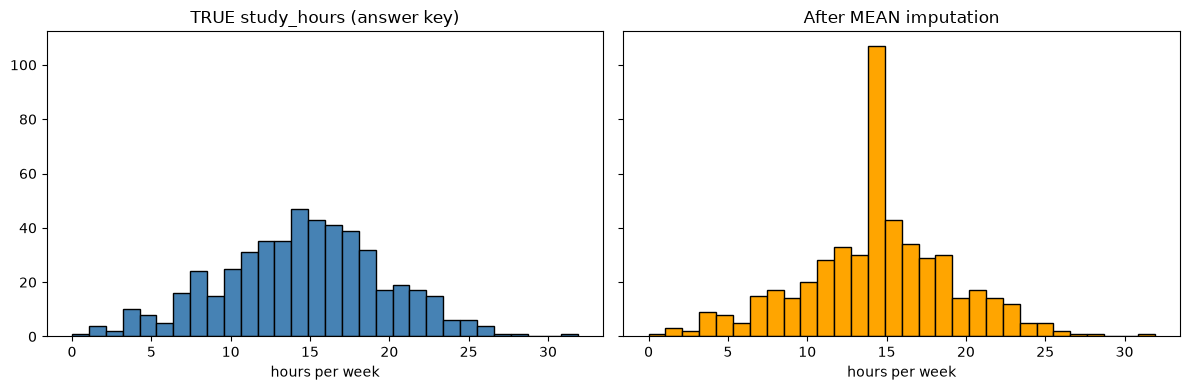

Std. deviation (true):          5.23
Std. deviation (mean-imputed):  4.83


In [60]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

axes[0].hist(df_true["study_hours"], bins=30, color="steelblue", edgecolor="black")
axes[0].set_title("TRUE study_hours (answer key)")
axes[0].set_xlabel("hours per week")

axes[1].hist(study_mean_imputed, bins=30, color="orange", edgecolor="black")
axes[1].set_title("After MEAN imputation")
axes[1].set_xlabel("hours per week")

plt.tight_layout()
plt.show()

print(f"Std. deviation (true):          {df_true['study_hours'].std():.2f}")
print(f"Std. deviation (mean-imputed):  {study_mean_imputed.std():.2f}")

See the tall spike in the middle of the orange histogram? That's roughly 70 students who all got exactly the same value. Consequences:

* The **standard deviation shrinks**, so the data looks less variable than it really is.
* **Relationships between columns get weaker**. Let's check the correlation between `study_hours` and `exam_score`:

In [25]:
print("Correlation(study_hours, exam_score)")
print(f"  true data:       {df_true['study_hours'].corr(df_true['exam_score']):.3f}")
print(f"  mean-imputed:    {study_mean_imputed.corr(df['exam_score']):.3f}")

Correlation(study_hours, exam_score)
  true data:       0.865
  mean-imputed:    0.792


**Why does the correlation drop?**


For the imputed students, `study_hours` is fixed at the mean no matter whether their exam score is 40 or 90. Those points form a flat horizontal line on a scatter plot, which "dilutes" the real upward trend. With only 15% missing the drop is small, but with more missingness it gets worse (you'll see this in Section 10).


### 5.5 Mean imputation with scikit-learn's `SimpleImputer`

Doing `fillna` column by column gets tedious. scikit-learn's **`SimpleImputer`** does it for many columns at once and follows the familiar sklearn pattern:

1. **Create** the imputer and choose a strategy: `SimpleImputer(strategy="mean")`
2. **`fit`** it: it *learns* the mean of each column.
3. **`transform`**: it *fills in* the gaps using what it learned.

(`fit_transform` does steps 2 and 3 in one go.)

**Watch out:** `strategy="mean"` only works on **numeric** columns, so we select those first.

In [61]:
numeric_cols = ["study_hours", "sleep_hours", "attendance", "commute_minutes", "exam_score"]

mean_imputer = SimpleImputer(strategy="mean")
mean_imputer.fit(df[numeric_cols])

# The imputer remembers what it learned in the attribute `statistics_`
print("Means learned by the imputer:")
print(pd.Series(mean_imputer.statistics_, index=numeric_cols).round(2))

Means learned by the imputer:
study_hours        14.43
sleep_hours         7.01
attendance         83.13
commute_minutes    24.11
exam_score         55.85
dtype: float64


In [62]:
# transform() returns a NumPy array, so we wrap it back into a DataFrame
df_mean = df.copy()
df_mean[numeric_cols] = mean_imputer.transform(df[numeric_cols])

print("Missing values left in numeric columns:", df_mean[numeric_cols].isna().sum().sum())
df_mean.head()

Missing values left in numeric columns: 0


,part_time_job,study_hours,sleep_hours,attendance,commute_minutes,transport,exam_score
0,No,23.2,5.5,91.0,14.0,NaN,76.4
1,No,16.5,7.2,86.0,20.0,Bus,72.7
2,No,18.9,7.7,88.0,17.0,Bus,62.2
3,No,15.7,7.4,93.0,13.0,Walk,63.0
4,Yes,12.1,7.6,77.0,17.0,Bus,46.4


**Tip:** If you prefer to always get a DataFrame back, you can call `mean_imputer.set_output(transform="pandas")` once, and then `transform` returns a DataFrame with the original column names.




## 6. Method 2: Median imputation

### 6.1 Why bother with the median?
The **median** is the middle value when the data is sorted. Unlike the mean, it is **robust to outliers**: a few extreme values can't drag it around.

Here's a tiny example. Six people's monthly rent (in hundreds), one of whom lives in a penthouse:

In [63]:
rent = pd.Series([8, 9, 9, 10, 11, 60])
print(f"Mean:   {rent.mean():.1f}")
print(f"Median: {rent.median():.1f}")

Mean:   17.8
Median: 9.5


The mean (17.8) doesn't describe *anyone* in the group well, while the median (9.5) is a much more typical value. For **skewed** data, the median is usually a better "typical value" to plug into the gaps.

### 6.2 Our skewed column: `commute_minutes`

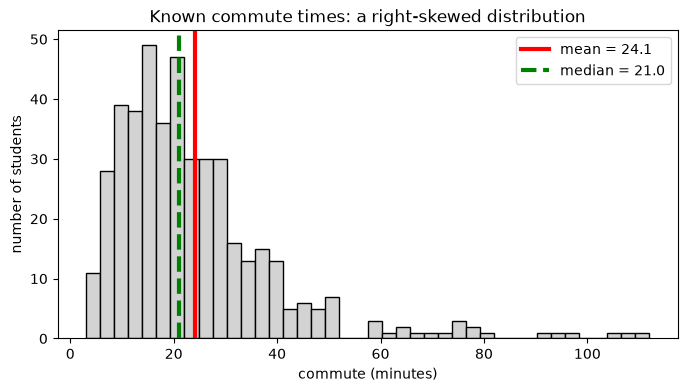

In [64]:
known_commute = df["commute_minutes"].dropna()

plt.hist(known_commute, bins=40, color="lightgray", edgecolor="black")
plt.axvline(known_commute.mean(), color="red", linewidth=3, label=f"mean = {known_commute.mean():.1f}")
plt.axvline(known_commute.median(), color="green", linewidth=3, linestyle="--",
            label=f"median = {known_commute.median():.1f}")
plt.xlabel("commute (minutes)")
plt.ylabel("number of students")
plt.title("Known commute times: a right-skewed distribution")
plt.legend()
plt.show()

The long tail on the right pulls the **mean** (red) to the right of where most students actually are. The **median** (green) sits closer to the big hump.

### 6.3 Mean vs. median on `commute_minutes`

In [65]:
commute_mean_imputed = df["commute_minutes"].fillna(df["commute_minutes"].mean())
commute_median_imputed = df["commute_minutes"].fillna(df["commute_minutes"].median())

pd.DataFrame({
    "mean imputation": grade_numeric(commute_mean_imputed, "commute_minutes"),
    "median imputation": grade_numeric(commute_median_imputed, "commute_minutes"),
})

,mean imputation,median imputation
MAE,9.97,9.39
RMSE,14.98,15.22


Look carefully at the two metrics. Does one method win on **both**?

Typically the **median wins on MAE** while the **mean does about as well or slightly better on RMSE**. That isn't a coincidence; it's a mathematical fact:

* The **median** is the single number that minimises the *average absolute error*.
* The **mean** is the single number that minimises the *average squared error*.

So "which is best" depends on how you measure. In practice, for skewed data, the median is usually preferred because it represents a **typical** student, and it isn't pushed around by a handful of extreme values. Neither method is great, though: both give every missing student the same number. Section 8 does much better.


### 6.4 Median imputation with `SimpleImputer`
Exactly the same as before; just change the strategy.

In [66]:
median_imputer = SimpleImputer(strategy="median")

df_median = df.copy()
df_median[numeric_cols] = median_imputer.fit_transform(df[numeric_cols])

print("Medians learned by the imputer:")
print(pd.Series(median_imputer.statistics_, index=numeric_cols).round(2))

Medians learned by the imputer:
study_hours        14.60
sleep_hours         7.00
attendance         84.00
commute_minutes    21.00
exam_score         56.45
dtype: float64


### 6.5 What about categorical columns? → "most frequent"
You can't take the mean of `"Walk"`, `"Bus"` and `"Car"`! For categories the simple equivalent is the **mode**: the most common value. In `SimpleImputer` this is `strategy="most_frequent"`.

In [67]:
print("Counts of known transport values:")
print(df["transport"].value_counts())

mode_imputer = SimpleImputer(strategy="most_frequent")
transport_mode_imputed = pd.Series(
    mode_imputer.fit_transform(df[["transport"]]).ravel(),   # ravel() flattens to 1-D
    index=df.index,
)
print("\nValue used to fill the gaps:", mode_imputer.statistics_[0])

Counts of known transport values:
transport
Bus     212
Walk    125
Car      82
Name: count, dtype: int64

Value used to fill the gaps: Bus


In [68]:
def grade_categorical(imputed_series, col):
    # Accuracy = fraction of the missing cells we guessed exactly right.
    missing = df[col].isna()
    correct = imputed_series[missing] == df_true.loc[missing, col]
    return {"accuracy": round(correct.mean(), 3)}

grade_categorical(transport_mode_imputed, "transport")

{'accuracy': np.float64(0.519)}

Filling with the mode is right only for students who happen to use the most common transport type. We'll try to beat this accuracy with a Random Forest Classifier.

## 7. The golden rule: avoid data leakage

So far we computed the mean/median on the **whole** dataset. That's fine for exploring, but when you build a machine-learning model you split your data into a **training set** and a **test set**. The test set is supposed to simulate *new, unseen data*.

**Rule:** learn the imputation values (the means, medians, or a Random Forest) from the **training set only**, then apply them to the test set.

If you compute the mean using the test set too, information from the "future" leaks into training, and your model's test score will look better than it really is. This mistake is called **data leakage**.

The `fit` / `transform` split in sklearn makes this easy to get right:

In [69]:
train_df, test_df = train_test_split(df, test_size=0.25, random_state=0)

imputer = SimpleImputer(strategy="median")
imputer.fit(train_df[numeric_cols])                 # learn medians from TRAIN only

train_imputed = imputer.transform(train_df[numeric_cols])   # fill train gaps
test_imputed = imputer.transform(test_df[numeric_cols])     # fill test gaps with TRAIN medians

print("Medians learned from the training set:")
print(pd.Series(imputer.statistics_, index=numeric_cols).round(2))

Medians learned from the training set:
study_hours        15.0
sleep_hours         7.1
attendance         84.0
commute_minutes    20.0
exam_score         57.4
dtype: float64


**Tip:** In real projects, put the imputer inside an sklearn **`Pipeline`** together with your model, e.g.

```python
from sklearn.pipeline import make_pipeline
model = make_pipeline(SimpleImputer(strategy="median"), RandomForestRegressor())
model.fit(X_train, y_train)
```

The pipeline then automatically fits the imputer on training data only. For the rest of this tutorial we impute the whole `df` to keep the code simple and focused on *how* imputation works.

## 8. Methods 3 & 4: Imputation with Random Forests

### 8.1 The big idea: a missing value is just something to *predict*
Mean and median imputation ignore the other columns. But our columns are related! A student who scored 90 on the exam probably studied more than one who scored 40. Let's use that.

Treat the column with gaps as the **target** (`y`) and the other columns as **features** (`X`):

```
              features (X)                       target (y)
  exam_score  attendance  part_time_job  ...  |  study_hours
  ------------------------------------------- | ------------
     78.1        92           No         ...  |    19.5     ┐
     55.0        71           Yes        ...  |    10.2     ├─ KNOWN rows   → TRAIN the model
     83.4        88           No         ...  |    21.0     ┘
     61.7        80           Yes        ...  |     NaN     ┐
     90.2        97           No         ...  |     NaN     ┘  MISSING rows → PREDICT
```

* If the target column is **numeric** → use a **`RandomForestRegressor`**.
* If the target column is **categorical** → use a **`RandomForestClassifier`**.

### 8.2 A 60-second Random Forest refresher
* A **decision tree** makes predictions by asking a sequence of yes/no questions ("Is exam_score > 70? Is attendance > 85?").
* A single tree tends to memorise its training data (overfitting).
* A **Random Forest** trains *many* trees, each on a random sample of rows and features, and combines them: it **averages** their predictions (regression) or takes a **majority vote** (classification).

Why it's a popular choice for imputation:
* Captures **non-linear** relationships and interactions automatically.
* Doesn't need feature scaling.
* Works reasonably well with default settings.

### 8.3 Random Forest **Regressor**: imputing `study_hours`, step by step

#### Step 1 — Choose the target and the features

In [71]:
target = "study_hours"
feature_cols = [c for c in df.columns if c != target]
print("Target:  ", target)
print("Features:", feature_cols)

Target:   study_hours
Features: ['part_time_job', 'sleep_hours', 'attendance', 'commute_minutes', 'transport', 'exam_score']


#### Step 2: Prepare the features
Random Forests in sklearn need **numeric** input, and some of our feature columns have their *own* holes. So:

1. **Temporarily** fill gaps in the *feature* columns with the median (numbers) or mode (categories). This is just to give the forest something to work with.
2. **Encode** the categorical columns as numbers:
   * `part_time_job`: `Yes` → 1, `No` → 0
   * `transport`: **one-hot encoding** with `pd.get_dummies`, which creates a separate 0/1 column for each category (`transport_Bus`, `transport_Car`, `transport_Walk`).

**Think back to what we learned about encoding:** Why not just encode `transport` as Walk = 0, Bus = 1, Car = 2?

That would invent a fake *order* and fake distances ("Car is twice as much as Bus"). One-hot encoding avoids implying any order. (Tree models are fairly forgiving about this, but one-hot encoding is the safe habit.)

**The chicken-and-egg problem:** to impute `study_hours` we need complete features, but the features have holes too! The temporary median/mode fill is a quick workaround. More advanced methods (Section 11) repeat the process in rounds so every column's imputation improves the others.

In [72]:
X = df[feature_cols].copy()

# 1) Temporary fill of gaps in the FEATURE columns
for col in X.columns:
    if pd.api.types.is_numeric_dtype(X[col]):
        X[col] = X[col].fillna(X[col].median())
    else:
        X[col] = X[col].fillna(X[col].mode()[0])

# 2) Encode categorical columns as numbers
X["part_time_job"] = (X["part_time_job"] == "Yes").astype(int)
X = pd.get_dummies(X, columns=["transport"], dtype=int)

print("Any NaN left in X?", X.isna().any().any())
X.head()

Any NaN left in X? False


,part_time_job,sleep_hours,attendance,commute_minutes,exam_score,transport_Bus,transport_Car,transport_Walk
0,0,5.5,91.0,14.0,76.4,1,0,0
1,0,7.2,86.0,20.0,72.7,1,0,0
2,0,7.7,88.0,17.0,62.2,1,0,0
3,0,7.4,93.0,13.0,63.0,0,0,1
4,1,7.6,77.0,17.0,46.4,1,0,0


#### Step 3: Split rows into "known" and "missing"

In [74]:
y = df[target]
is_missing = y.isna()

X_known, y_known = X[~is_missing], y[~is_missing]   # ~ means "NOT"
X_missing = X[is_missing]

print(f"Rows used for training (target known): {len(X_known)}")
print(f"Rows to impute (target missing):       {len(X_missing)}")

Rows used for training (target known): 432
Rows to impute (target missing):       68


#### Step 4: Train the Random Forest on the known rows
Key parameters:
* `n_estimators=200` — number of trees in the forest (more = more stable, but slower).
* `random_state=0` — makes results reproducible.
* `n_jobs=-1` — use all CPU cores to train faster.

In [75]:
rf_reg = RandomForestRegressor(n_estimators=200, random_state=0, n_jobs=-1)
rf_reg.fit(X_known, y_known)
print("Model trained!")

Model trained!


#### Step 5: Predict the missing values and fill them in

In [76]:
study_rf_imputed = y.copy()
study_rf_imputed[is_missing] = rf_reg.predict(X_missing)

# Notice: every imputed student now gets their OWN value, unlike mean imputation
pd.DataFrame({
    "true value": df_true.loc[is_missing, "study_hours"],
    "mean imputed": study_mean_imputed[is_missing].round(1),
    "RF imputed": study_rf_imputed[is_missing].round(1),
}).head(10)

,true value,mean imputed,RF imputed
10,14.8,14.4,13.7
11,14.6,14.4,14.2
18,8.5,14.4,4.8
22,8.5,14.4,9.7
23,1.2,14.4,4.7
47,14.3,14.4,13.5
52,18.3,14.4,19.2
58,9.1,14.4,9.2
61,17.2,14.4,22.8
72,26.2,14.4,25.5


#### Step 6: Grade it

In [77]:
pd.DataFrame({
    "mean": grade_numeric(study_mean_imputed, "study_hours"),
    "median": grade_numeric(df["study_hours"].fillna(df["study_hours"].median()), "study_hours"),
    "random forest": grade_numeric(study_rf_imputed, "study_hours"),
})

,mean,median,random forest
MAE,4.37,4.35,1.94
RMSE,5.40,5.38,2.50


The Random Forest's error should be clearly lower: it used each student's exam score, job status, etc. to make a *personalised* guess.

Let's visualise this. On a scatter plot of **true** vs **imputed** values, a perfect imputer would put every point on the diagonal line.

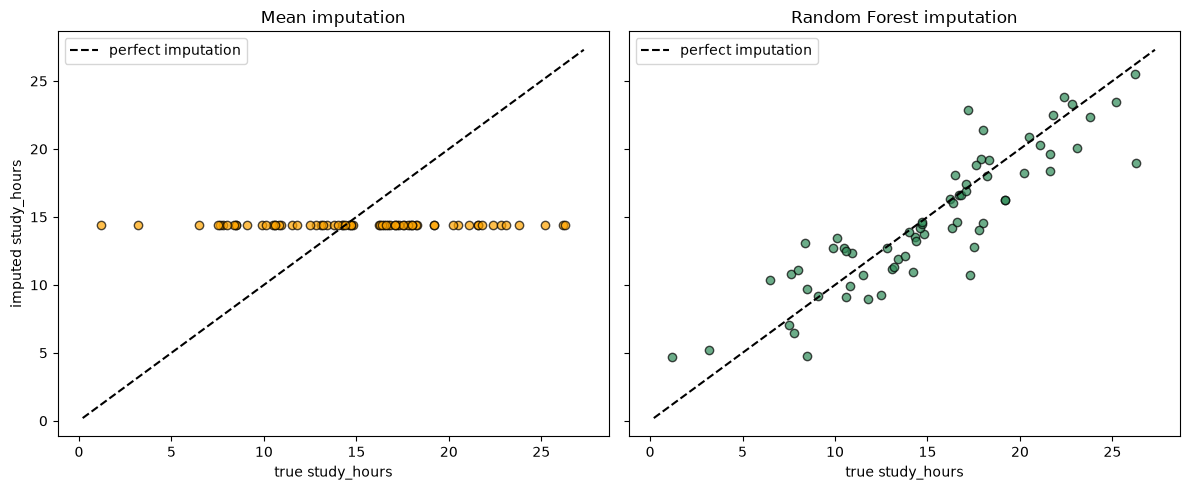

In [78]:
true_vals = df_true.loc[is_missing, "study_hours"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, imputed, title, color in [
    (axes[0], study_mean_imputed, "Mean imputation", "orange"),
    (axes[1], study_rf_imputed, "Random Forest imputation", "seagreen"),
]:
    ax.scatter(true_vals, imputed[is_missing], alpha=0.7, color=color, edgecolor="black")
    lims = [true_vals.min() - 1, true_vals.max() + 1]
    ax.plot(lims, lims, "k--", label="perfect imputation")
    ax.set_title(title)
    ax.set_xlabel("true study_hours")
    ax.legend()
axes[0].set_ylabel("imputed study_hours")
plt.tight_layout()
plt.show()

Mean imputation is a flat line: it predicts the same value for everyone. The Random Forest points follow the diagonal, imperfectly but far better.

#### Bonus: which features helped the most?
Random Forests can tell us how much each feature contributed via `feature_importances_` (the values sum to 1).

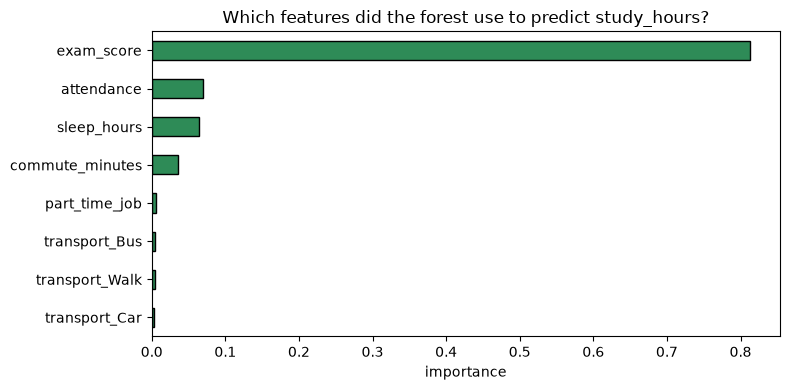

In [79]:
importances = pd.Series(rf_reg.feature_importances_, index=X.columns).sort_values()
importances.plot(kind="barh", color="seagreen", edgecolor="black")
plt.title("Which features did the forest use to predict study_hours?")
plt.xlabel("importance")
plt.tight_layout()
plt.show()

Does the top feature make sense, given how we generated the data in Section 1?

`exam_score` should dominate. We built the exam score as `30 + 2.0 × study_hours + ...`, so knowing the score tells you a lot about study time. The forest discovered this relationship on its own. Features like `transport` that have nothing to do with studying get very low importance.


### 8.4 Random Forest **Classifier**: imputing `transport`

The recipe is identical. The only changes: the target is now categorical, so we use **`RandomForestClassifier`**, and accuracy replaces MAE/RMSE.

This time `commute_minutes` should be the hero feature, since transport choice depends on commute length.

In [80]:
target = "transport"
feature_cols = [c for c in df.columns if c != target]

# Step 2: prepare features (temporary fill + encoding)
X = df[feature_cols].copy()
for col in X.columns:
    if pd.api.types.is_numeric_dtype(X[col]):
        X[col] = X[col].fillna(X[col].median())
    else:
        X[col] = X[col].fillna(X[col].mode()[0])
X["part_time_job"] = (X["part_time_job"] == "Yes").astype(int)
# (transport is the target now, so there's nothing to one-hot encode in X)

# Step 3: split known vs missing
y = df[target]
is_missing = y.isna()

# Step 4: train
rf_clf = RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1)
rf_clf.fit(X[~is_missing], y[~is_missing])

# Step 5: predict and fill
transport_rf_imputed = y.copy()
transport_rf_imputed[is_missing] = rf_clf.predict(X[is_missing])

# Step 6: grade
pd.DataFrame({
    "most frequent (mode)": grade_categorical(transport_mode_imputed, "transport"),
    "random forest": grade_categorical(transport_rf_imputed, "transport"),
})

,most frequent (mode),random forest
accuracy,0.52,0.86


A big jump in accuracy! Let's see *where* the classifier gets things right and wrong with a **confusion table** (rows = truth, columns = prediction). Correct guesses lie on the diagonal.

In [81]:
pd.crosstab(
    df_true.loc[is_missing, "transport"],
    transport_rf_imputed[is_missing],
    rownames=["TRUE"], colnames=["PREDICTED"],
)

PREDICTED,Bus,Car,Walk
TRUE,,,
Bus,39,2,1
Car,1,13,2
Walk,5,0,18


Remember that when we built the data, 15% of students were assigned a **random** transport type, regardless of their commute. What does that imply about the *best possible* accuracy any imputer could achieve?


Those randomly assigned students are essentially unpredictable from the other columns, so no method can reach 100%. Some missing information is genuinely gone. Imputation gives you a **best guess**, never the truth.

**Important:** A classifier can also tell you *how confident* it is. `rf_clf.predict_proba(X[is_missing])` returns the probability of each class for each row. Try it in the cell below!

### 8.5 Packaging it up: a reusable `rf_impute` function
We just wrote almost the same code twice. Good programmers wrap repeated logic in a function. This one:
* checks whether the target column is numeric or categorical,
* picks a regressor or classifier accordingly,
* returns the column with its gaps filled in.

Read through it and match each part to the 6 steps above.

In [82]:
def rf_impute(data, target, n_estimators=200, random_state=0):
    # Impute missing values in data[target] with a Random Forest.
    # Returns a new Series; `data` itself is not changed.
    y = data[target]
    is_missing = y.isna()
    if not is_missing.any():
        return y.copy()                                   # nothing to do

    # Step 2: prepare features
    X = data.drop(columns=[target]).copy()
    for col in X.columns:                                 # temporary fill of feature gaps
        if pd.api.types.is_numeric_dtype(X[col]):
            X[col] = X[col].fillna(X[col].median())
        else:
            X[col] = X[col].fillna(X[col].mode()[0])
    X = pd.get_dummies(X, dtype=int)                      # one-hot encode ALL text columns

    # Step 1 (continued): choose the right kind of model
    if pd.api.types.is_numeric_dtype(y):
        model = RandomForestRegressor(n_estimators=n_estimators, random_state=random_state, n_jobs=-1)
    else:
        model = RandomForestClassifier(n_estimators=n_estimators, random_state=random_state, n_jobs=-1)

    # Steps 3-5: train on known rows, predict missing rows
    model.fit(X[~is_missing], y[~is_missing])
    result = y.copy()
    result[is_missing] = model.predict(X[is_missing])
    return result

Note that `pd.get_dummies(X)` on the whole DataFrame turns `part_time_job` into two columns (`part_time_job_No`, `part_time_job_Yes`). That's slightly redundant but perfectly fine for a Random Forest.

Now let's impute **every** column that has gaps in one short loop:

In [83]:
df_rf = df.copy()
for col in df.columns[df.isna().any()]:        # only columns that contain NaN
    df_rf[col] = rf_impute(df, col)            # note: features always come from the ORIGINAL df
    print(f"Imputed {col}")

print("\nMissing values left:", df_rf.isna().sum().sum())
df_rf.head()

Imputed study_hours
Imputed sleep_hours
Imputed commute_minutes
Imputed transport

Missing values left: 0


,part_time_job,study_hours,sleep_hours,attendance,commute_minutes,transport,exam_score
0,No,23.2,5.5,91.0,14.0,Walk,76.4
1,No,16.5,7.2,86.0,20.0,Bus,72.7
2,No,18.9,7.7,88.0,17.0,Bus,62.2
3,No,15.7,7.4,93.0,13.0,Walk,63.0
4,Yes,12.1,7.6,77.0,17.0,Bus,46.4


## Summary cheat sheet

| Method | Code | Good when... | Watch out for... |
|--------|------|-------------|------------------|
| Drop rows | `df.dropna()` | Very few rows affected and data is MCAR | Throwing away lots of data; bias |
| **Mean** | `SimpleImputer(strategy="mean")` | Numeric, roughly symmetric, few gaps | Outliers; shrinks variance & correlations |
| **Median** | `SimpleImputer(strategy="median")` | Numeric, **skewed** or with outliers | Same constant-value problems as the mean |
| Most frequent | `SimpleImputer(strategy="most_frequent")` | Categorical, quick baseline | Over-represents the most common category |
| **RF Regressor** | train on known rows → `predict` missing | Numeric column **related** to other columns | Slower; needs encoding; no help if columns are unrelated |
| **RF Classifier** | same recipe, classifier | Categorical column related to other columns | Same as above |
| Iterative (missForest-style) | `IterativeImputer(estimator=RandomForestRegressor())` | Many columns with gaps | Slowest; still experimental in sklearn |

### Key takeaways
1. **Always explore first**: `df.isna().sum()` and `df.isna().mean()`.
2. Simple imputation is a fine **baseline**, but it gives everyone the same value, which **shrinks spread** and **weakens relationships**.
3. Use the **median** for skewed data.
4. Model-based imputation (Random Forest) treats each gap as a **prediction problem** and is usually more accurate when columns are related.
5. **Fit imputers on training data only** to avoid data leakage; a `Pipeline` does this for you.
6. Imputed values are **educated guesses**, not real data. Be honest about that in any report.